# Assignment 3: PCA, SVD and LDA on the ORL Face Dataset

**Objective:** Apply three classical linear dimensionality-reduction techniques to the ORL (Olivetti) face database and compare them.

| Technique | Type | Idea |
|---|---|---|
| **PCA** | Unsupervised | Project onto directions of maximum variance (eigenfaces) |
| **SVD** | Unsupervised | Factorise the centred data matrix `X = U S Vᵀ`; gives the same subspace as PCA and low-rank approximations |
| **LDA** | Supervised | Project onto directions that maximise between-class / within-class scatter (Fisherfaces) |


## 1. Imports and Setup

In [1]:
import os, glob, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

warnings.filterwarnings("ignore")
np.random.seed(42)
plt.rcParams["figure.dpi"] = 110

## 2. Load the ORL Dataset

By default the notebook downloads the Olivetti faces through scikit-learn (this is the ORL database).
If you have the original ORL folder (`s1/1.pgm ... s40/10.pgm`, 92x112 images), set `LOCAL_ORL_DIR` to its path.

In [2]:
LOCAL_ORL_DIR = None   # e.g. "/content/orl_faces" ; None -> use sklearn's copy

def load_orl_local(root, size=(64, 64)):
    from PIL import Image
    X, y = [], []
    for s in range(1, 41):
        for i in range(1, 11):
            path = os.path.join(root, f"s{s}", f"{i}.pgm")
            img = Image.open(path).convert("L").resize(size[::-1])
            X.append(np.asarray(img, dtype=np.float64).ravel() / 255.0)
            y.append(s - 1)
    return np.array(X), np.array(y)

if LOCAL_ORL_DIR:
    IMG_SHAPE = (64, 64)
    X, y = load_orl_local(LOCAL_ORL_DIR, IMG_SHAPE)
else:
    from sklearn.datasets import fetch_olivetti_faces
    faces = fetch_olivetti_faces(shuffle=False)
    X, y = faces.data, faces.target
    IMG_SHAPE = (64, 64)

n_samples, n_features = X.shape
n_classes = len(np.unique(y))
print(f"Images: {n_samples}, features (pixels): {n_features}, subjects: {n_classes}")
print(f"Pixel range: [{X.min():.2f}, {X.max():.2f}]")

Images: 400, features (pixels): 4096, subjects: 40
Pixel range: [0.00, 1.00]


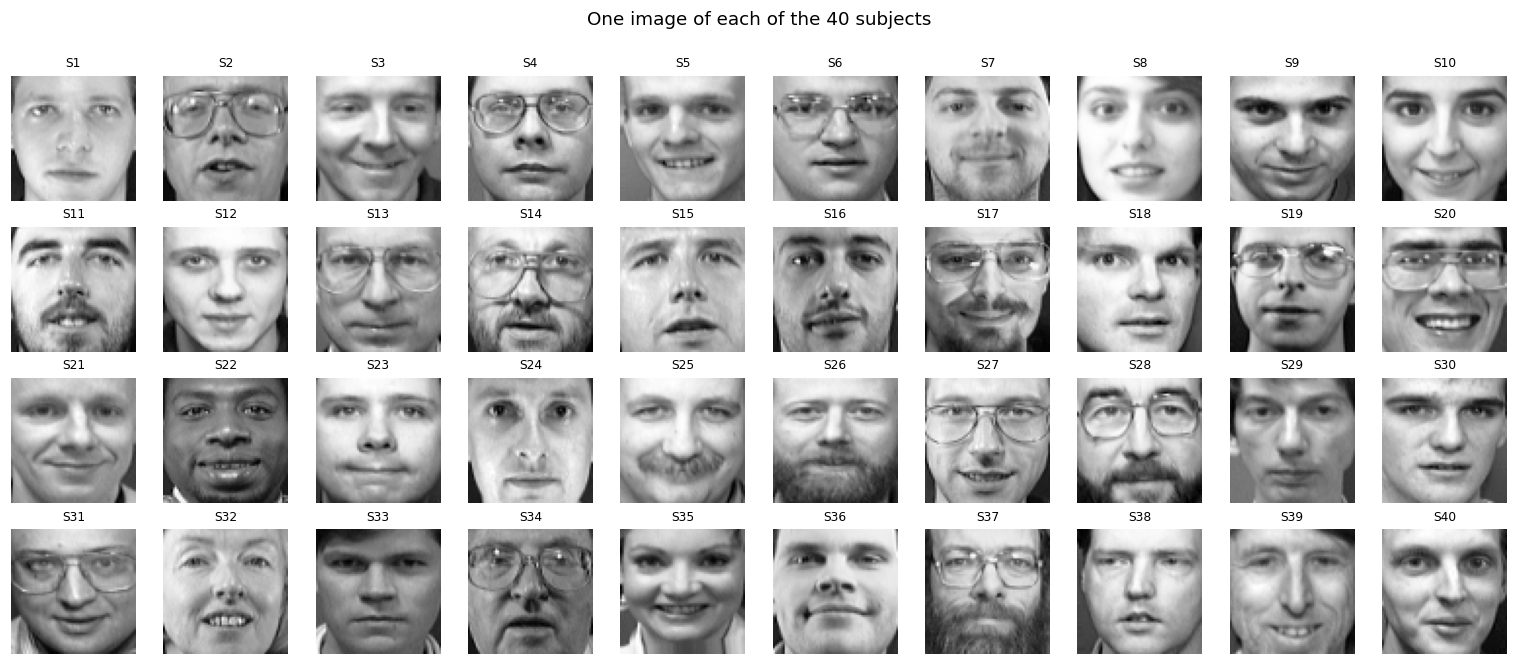

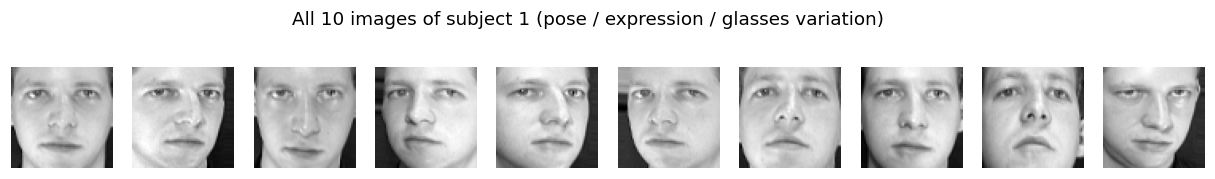

In [3]:
fig, axes = plt.subplots(4, 10, figsize=(14, 6))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(X[i * 10].reshape(IMG_SHAPE), cmap="gray")
    ax.set_title(f"S{y[i*10]+1}", fontsize=8)
    ax.axis("off")
plt.suptitle("One image of each of the 40 subjects", y=1.0)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 10, figsize=(14, 2))
for i, ax in enumerate(axes):
    ax.imshow(X[i].reshape(IMG_SHAPE), cmap="gray"); ax.axis("off")
plt.suptitle("All 10 images of subject 1 (pose / expression / glasses variation)")
plt.show()

## 3. Train / Test Split
Stratified 70/30 split so every subject appears in both sets (7 train and 3 test images per subject).

Train: (280, 4096)  Test: (120, 4096)


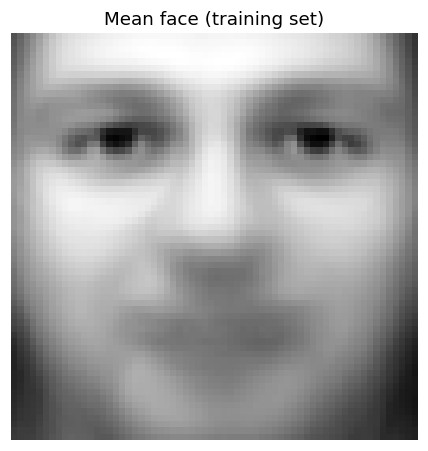

Baseline 1-NN accuracy on raw pixels (4096 dims): 0.9250


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

mean_face = X_train.mean(axis=0)
plt.imshow(mean_face.reshape(IMG_SHAPE), cmap="gray"); plt.title("Mean face (training set)"); plt.axis("off"); plt.show()

def knn_acc(Ztr, Zte, k=1):
    clf = KNeighborsClassifier(n_neighbors=k).fit(Ztr, y_train)
    return accuracy_score(y_test, clf.predict(Zte))

base_acc = knn_acc(X_train, X_test)
print(f"Baseline 1-NN accuracy on raw pixels ({n_features} dims): {base_acc:.4f}")

## 4. Principal Component Analysis (PCA)

PCA finds an orthonormal basis that maximises variance. Steps:
1. Centre the data: `Xc = X - mean`
2. Covariance matrix `C = XcᵀXc / (n-1)` (4096x4096)
3. Eigen-decomposition `C v = λ v`; sort by descending λ
4. Project onto the top-k eigenvectors: `Z = Xc V_k`

Because `n (=280) << d (=4096)`, we use the *Turk-Pentland trick*: eigen-decompose the small `n x n` Gram matrix `XcXcᵀ`
and map its eigenvectors back to pixel space (`v = Xcᵀ u / ||Xcᵀ u||`). This gives the same non-zero eigenpairs much faster.

In [5]:
# ---- PCA from scratch ----
Xc = X_train - mean_face
n = Xc.shape[0]

gram = (Xc @ Xc.T) / (n - 1)                 # n x n
eigvals, U = np.linalg.eigh(gram)
idx = np.argsort(eigvals)[::-1]
eigvals, U = eigvals[idx], U[:, idx]

keep = eigvals > 1e-10                       # drop numerically-zero components
eigvals, U = eigvals[keep], U[:, keep]

V = Xc.T @ U                                 # d x r
V /= np.linalg.norm(V, axis=0)               # unit-length eigenfaces
print("Number of non-zero principal components:", V.shape[1])

# ---- Compare with sklearn ----
pca_full = PCA(svd_solver="full").fit(X_train)
r = 10
print("\nTop-5 eigenvalues  (scratch):", np.round(eigvals[:5], 5))
print("Top-5 eigenvalues  (sklearn):", np.round(pca_full.explained_variance_[:5], 5))
print("Max |difference| in first 10 eigenvalues:", np.abs(eigvals[:r] - pca_full.explained_variance_[:r]).max())

Number of non-zero principal components: 280

Top-5 eigenvalues  (scratch): [19.61857 10.2235   6.45576  3.89387  2.90111]
Top-5 eigenvalues  (sklearn): [19.61856 10.2235   6.45576  3.89387  2.90111]
Max |difference| in first 10 eigenvalues: 5.722046e-06


90% variance needs 59 components
95% variance needs 104 components
99% variance needs 200 components


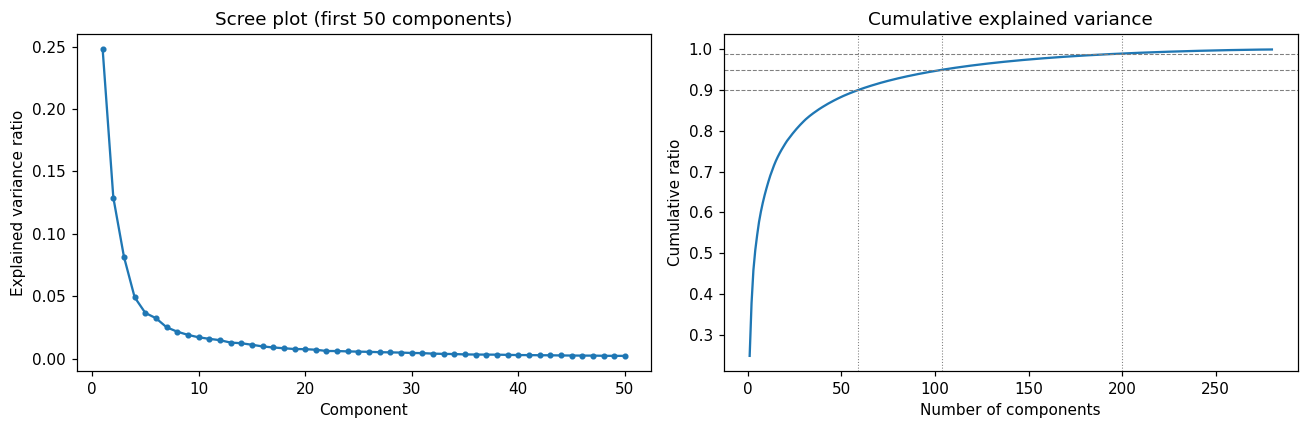

In [6]:
# ---- Explained variance ----
evr = eigvals / eigvals.sum()
cum = np.cumsum(evr)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(1, 51), evr[:50], "o-", ms=3)
ax[0].set_title("Scree plot (first 50 components)"); ax[0].set_xlabel("Component"); ax[0].set_ylabel("Explained variance ratio")
ax[1].plot(range(1, len(cum) + 1), cum)
for thr in (0.90, 0.95, 0.99):
    k = int(np.searchsorted(cum, thr) + 1)
    ax[1].axhline(thr, ls="--", c="gray", lw=0.7); ax[1].axvline(k, ls=":", c="gray", lw=0.7)
    print(f"{int(thr*100)}% variance needs {k} components")
ax[1].set_title("Cumulative explained variance"); ax[1].set_xlabel("Number of components"); ax[1].set_ylabel("Cumulative ratio")
plt.tight_layout(); plt.show()

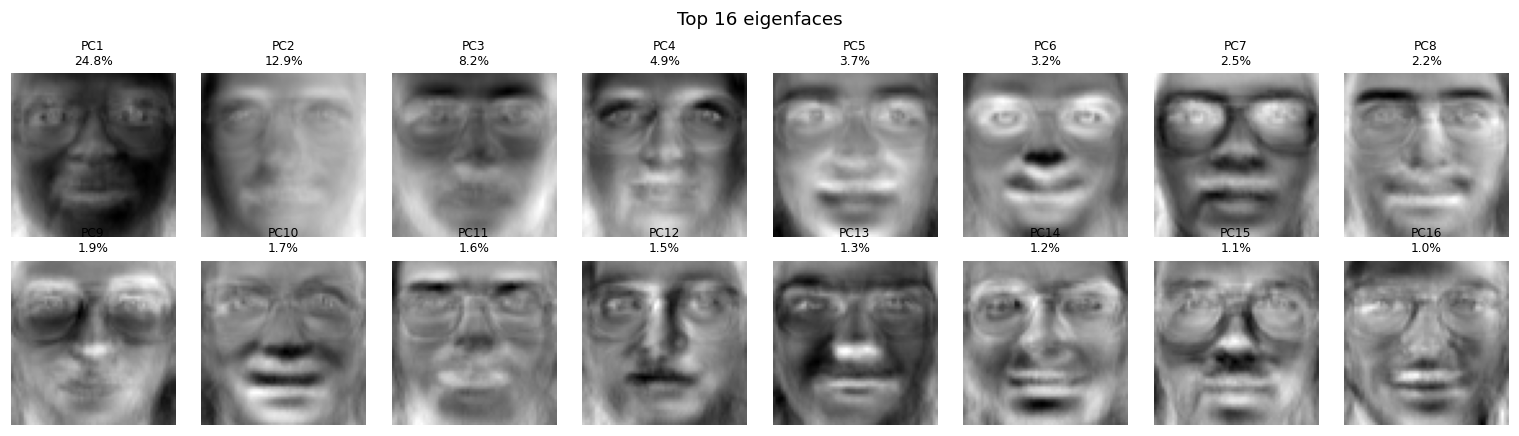

In [7]:
# ---- Eigenfaces ----
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(V[:, i].reshape(IMG_SHAPE), cmap="gray")
    ax.set_title(f"PC{i+1}\n{evr[i]*100:.1f}%", fontsize=8); ax.axis("off")
plt.suptitle("Top 16 eigenfaces"); plt.tight_layout(); plt.show()

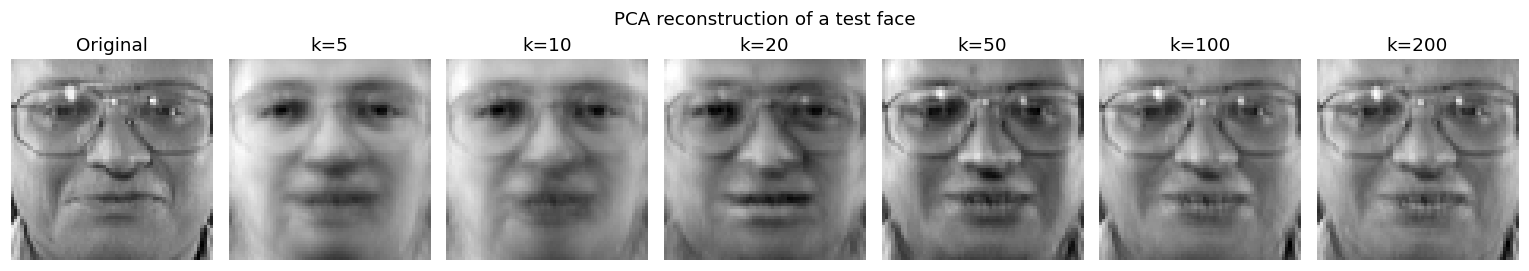

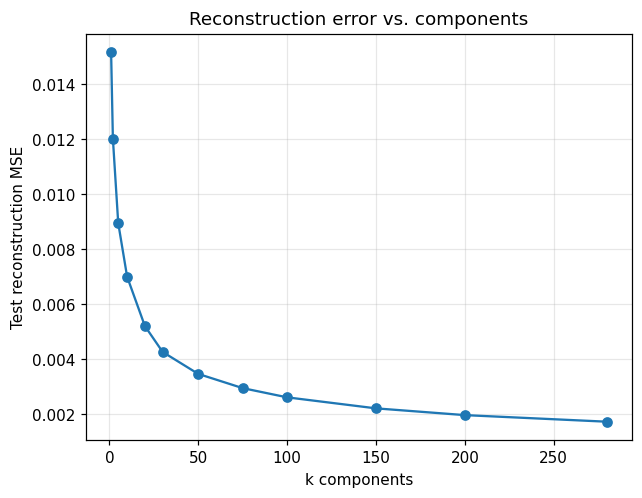

In [8]:
# ---- Reconstruction with different numbers of components ----
def pca_reconstruct(x, k):
    z = (x - mean_face) @ V[:, :k]
    return mean_face + z @ V[:, :k].T

ks = [5, 10, 20, 50, 100, 200]
sample = X_test[0]
fig, axes = plt.subplots(1, len(ks) + 1, figsize=(14, 2.5))
axes[0].imshow(sample.reshape(IMG_SHAPE), cmap="gray"); axes[0].set_title("Original"); axes[0].axis("off")
for ax, k in zip(axes[1:], ks):
    ax.imshow(pca_reconstruct(sample, k).reshape(IMG_SHAPE), cmap="gray"); ax.set_title(f"k={k}"); ax.axis("off")
plt.suptitle("PCA reconstruction of a test face"); plt.tight_layout(); plt.show()

# reconstruction MSE vs k
ks_range = [1, 2, 5, 10, 20, 30, 50, 75, 100, 150, 200, V.shape[1]]
mse = [np.mean((X_test - np.array([pca_reconstruct(x, k) for x in X_test])) ** 2) for k in ks_range]
plt.plot(ks_range, mse, "o-"); plt.xlabel("k components"); plt.ylabel("Test reconstruction MSE")
plt.title("Reconstruction error vs. components"); plt.grid(alpha=.3); plt.show()

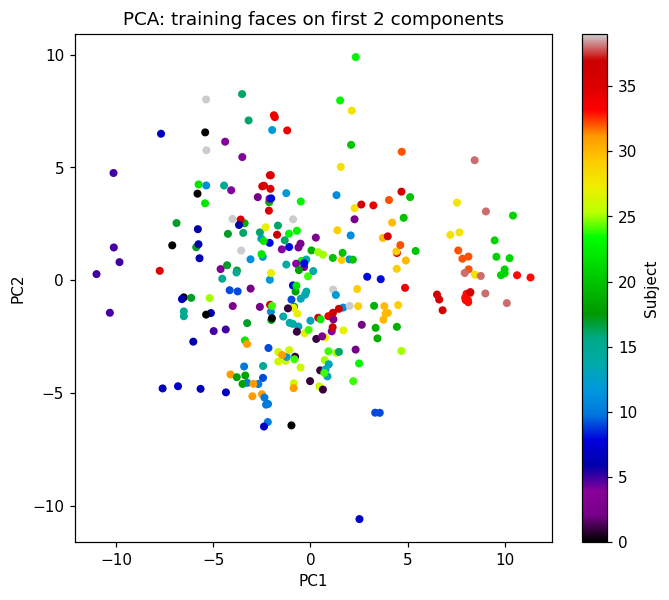

In [9]:
# ---- 2-D and 3-D PCA projections ----
Z2 = (X_train - mean_face) @ V[:, :2]
plt.figure(figsize=(7, 6))
sc = plt.scatter(Z2[:, 0], Z2[:, 1], c=y_train, cmap="nipy_spectral", s=18)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("PCA: training faces on first 2 components")
plt.colorbar(sc, label="Subject"); plt.show()

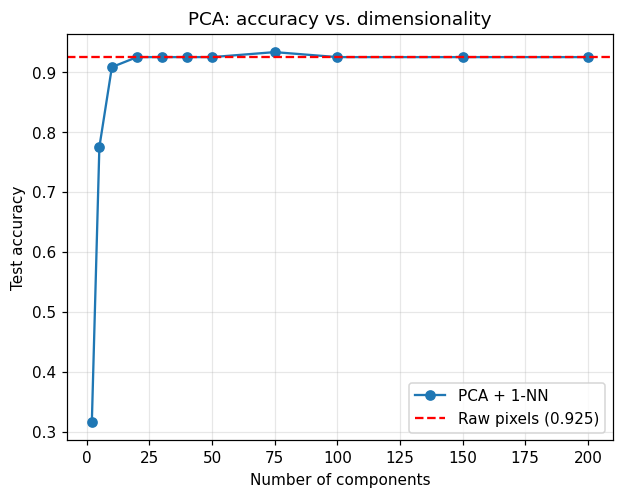

,components,accuracy
0,2,0.3167
1,5,0.7750
2,10,0.9083
3,20,0.9250
4,30,0.9250
5,40,0.9250
6,50,0.9250
7,75,0.9333
8,100,0.9250
9,150,0.9250


In [10]:
# ---- Classification accuracy vs number of PCA components (1-NN) ----
ks_cls = [2, 5, 10, 20, 30, 40, 50, 75, 100, 150, 200]
pca_accs = []
for k in ks_cls:
    Ztr = (X_train - mean_face) @ V[:, :k]
    Zte = (X_test - mean_face) @ V[:, :k]
    pca_accs.append(knn_acc(Ztr, Zte))

plt.plot(ks_cls, pca_accs, "o-", label="PCA + 1-NN")
plt.axhline(base_acc, color="r", ls="--", label=f"Raw pixels ({base_acc:.3f})")
plt.xlabel("Number of components"); plt.ylabel("Test accuracy"); plt.title("PCA: accuracy vs. dimensionality")
plt.legend(); plt.grid(alpha=.3); plt.show()
pd.DataFrame({"components": ks_cls, "accuracy": np.round(pca_accs, 4)})

In [11]:
best_k_pca = ks_cls[int(np.argmax(pca_accs))]
best_acc_pca = max(pca_accs)
print(f"Best PCA setting: k={best_k_pca}, accuracy={best_acc_pca:.4f}")

Best PCA setting: k=75, accuracy=0.9333


## 5. Singular Value Decomposition (SVD)

For the centred data matrix `Xc` (n x d):

`Xc = U Σ Vᵀ`

* columns of `V` = principal directions (same as PCA eigenvectors, up to sign)
* eigenvalues of the covariance matrix: `λᵢ = σᵢ² / (n-1)`
* projections: `Z = Xc V_k = U_k Σ_k`
* best rank-k approximation (Eckart-Young): `X_k = U_k Σ_k V_kᵀ`

In [12]:
U_svd, S, Vt = np.linalg.svd(Xc, full_matrices=False)
print("U:", U_svd.shape, " S:", S.shape, " Vt:", Vt.shape)

# --- Equivalence with PCA ---
svd_eigvals = S ** 2 / (n - 1)
print("\nTop-5 eigenvalues from SVD :", np.round(svd_eigvals[:5], 5))
print("Top-5 eigenvalues from PCA :", np.round(eigvals[:5], 5))

# Compare directions up to sign
cos = np.abs(np.sum(Vt[:10].T * V[:, :10], axis=0))
print("|cos| between SVD and PCA directions (first 10):", np.round(cos, 4))

U: (280, 280)  S: (280,)  Vt: (280, 4096)

Top-5 eigenvalues from SVD : [19.61857 10.2235   6.45576  3.89387  2.90111]
Top-5 eigenvalues from PCA : [19.61857 10.2235   6.45576  3.89387  2.90111]
|cos| between SVD and PCA directions (first 10): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


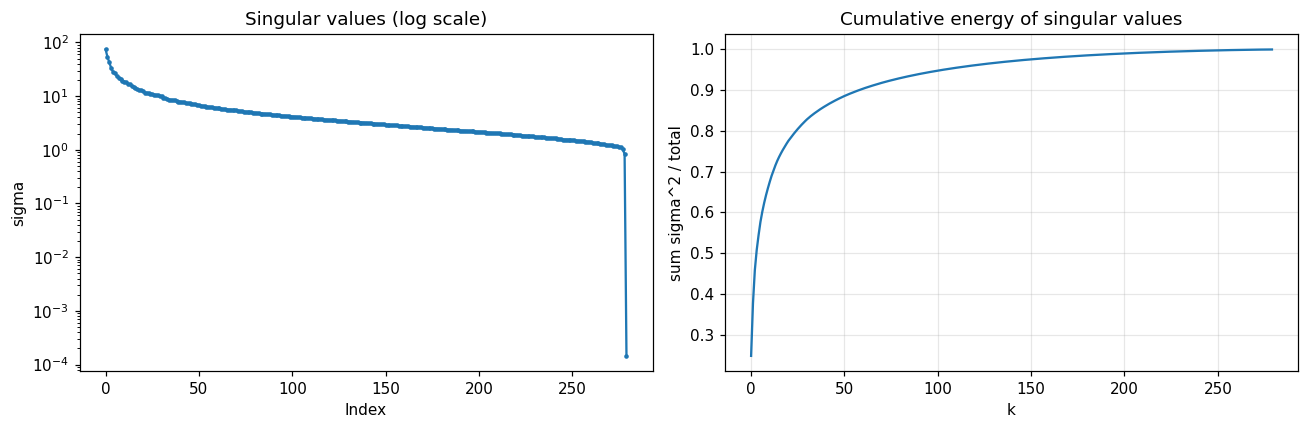

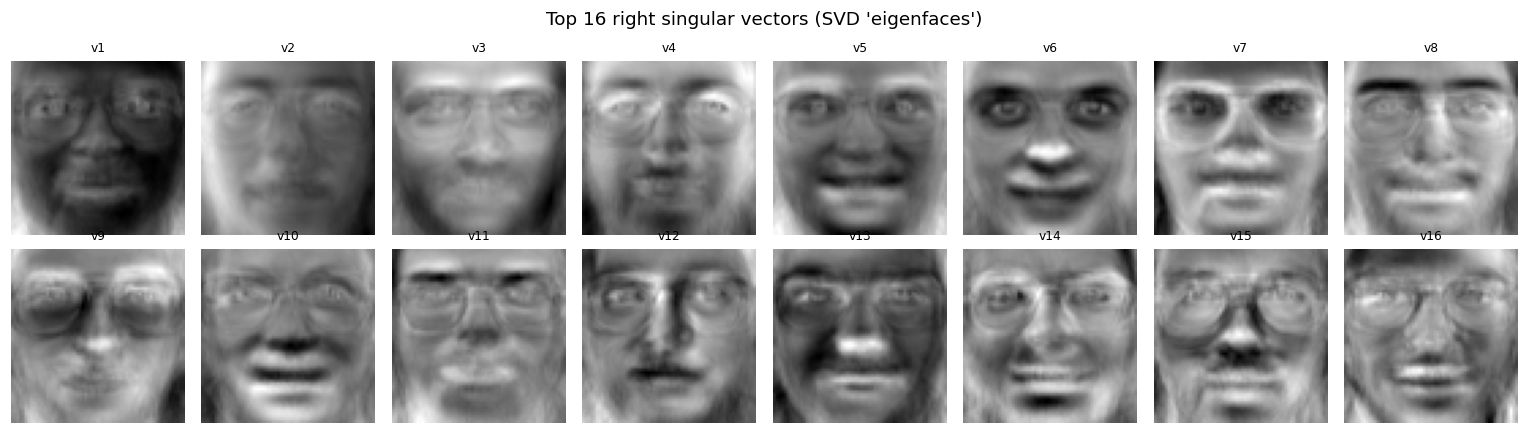

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(S, "o-", ms=2); ax[0].set_yscale("log")
ax[0].set_title("Singular values (log scale)"); ax[0].set_xlabel("Index"); ax[0].set_ylabel("sigma")
energy = np.cumsum(S ** 2) / np.sum(S ** 2)
ax[1].plot(energy); ax[1].set_title("Cumulative energy of singular values")
ax[1].set_xlabel("k"); ax[1].set_ylabel("sum sigma^2 / total"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(Vt[i].reshape(IMG_SHAPE), cmap="gray"); ax.set_title(f"v{i+1}", fontsize=8); ax.axis("off")
plt.suptitle("Top 16 right singular vectors (SVD 'eigenfaces')"); plt.tight_layout(); plt.show()

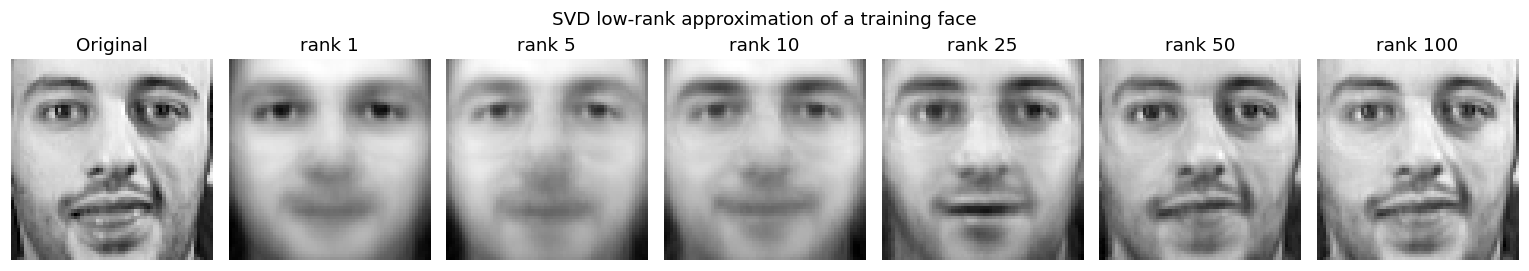

,rank k,relative error,energy kept,compression ratio
0,5,0.6751,0.5443,52.40
1,10,0.5835,0.6595,26.20
2,20,0.4809,0.7688,13.10
3,50,0.3410,0.8837,5.24
4,100,0.2297,0.9473,2.62
5,200,0.0997,0.9901,1.31


In [14]:
# ---- Low-rank approximation ----
def svd_lowrank(k):
    return mean_face + (U_svd[:, :k] * S[:k]) @ Vt[:k]

ks_show = [1, 5, 10, 25, 50, 100]
idx_img = 0
fig, axes = plt.subplots(1, len(ks_show) + 1, figsize=(14, 2.5))
axes[0].imshow(X_train[idx_img].reshape(IMG_SHAPE), cmap="gray"); axes[0].set_title("Original"); axes[0].axis("off")
for ax, k in zip(axes[1:], ks_show):
    ax.imshow(svd_lowrank(k)[idx_img].reshape(IMG_SHAPE), cmap="gray"); ax.set_title(f"rank {k}"); ax.axis("off")
plt.suptitle("SVD low-rank approximation of a training face"); plt.tight_layout(); plt.show()

# Relative Frobenius error and compression ratio
rows = []
for k in [5, 10, 20, 50, 100, 200]:
    rel_err = np.sqrt(1 - np.sum(S[:k] ** 2) / np.sum(S ** 2))
    stored = k * (n + n_features + 1)
    rows.append([k, round(rel_err, 4), round(1 - rel_err ** 2, 4), round(n * n_features / stored, 2)])
pd.DataFrame(rows, columns=["rank k", "relative error", "energy kept", "compression ratio"])

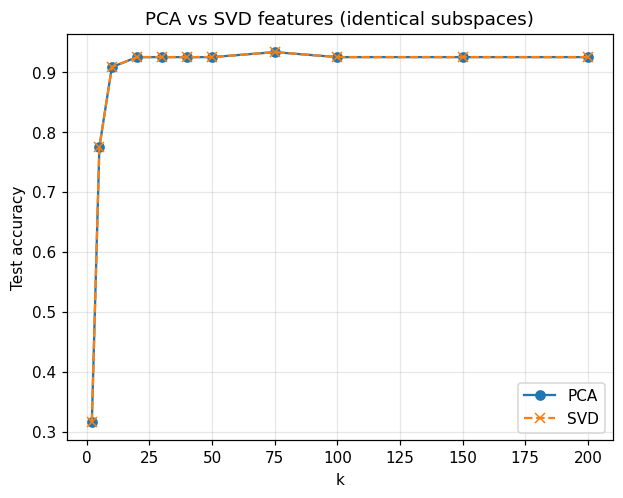

Best SVD setting: k=75, accuracy=0.9333
Max accuracy difference PCA vs SVD: 0.0


In [15]:
# ---- Classification with SVD features ----
svd_accs = []
for k in ks_cls:
    Ztr = Xc @ Vt[:k].T                       # = U_k * S_k
    Zte = (X_test - mean_face) @ Vt[:k].T
    svd_accs.append(knn_acc(Ztr, Zte))

plt.plot(ks_cls, pca_accs, "o-", label="PCA")
plt.plot(ks_cls, svd_accs, "x--", label="SVD")
plt.xlabel("k"); plt.ylabel("Test accuracy"); plt.legend(); plt.grid(alpha=.3)
plt.title("PCA vs SVD features (identical subspaces)"); plt.show()

best_k_svd = ks_cls[int(np.argmax(svd_accs))]; best_acc_svd = max(svd_accs)
print(f"Best SVD setting: k={best_k_svd}, accuracy={best_acc_svd:.4f}")
print("Max accuracy difference PCA vs SVD:", np.max(np.abs(np.array(pca_accs) - np.array(svd_accs))))

## 6. Linear Discriminant Analysis (LDA / Fisherfaces)

LDA maximises the Fisher criterion

`J(W) = |Wᵀ S_B W| / |Wᵀ S_W W|`

where `S_W` is the within-class scatter and `S_B` the between-class scatter. The solution is given by the top eigenvectors of `S_W⁻¹ S_B`; there are at most **C - 1 = 39** useful discriminant directions.

**Small-sample-size problem:** the number of training images (280) is far smaller than the number of pixels (4096), so `S_W` is singular. The standard fix (Belhumeur et al., *Fisherfaces*) is to first reduce dimensionality with PCA to at most `N - C` dimensions and then apply LDA.

In [16]:
# ---- Step 1: PCA to N - C dims (or fewer) ----
N_PCA = min(n - n_classes, 100)
V_pca = V[:, :N_PCA]
Ptr = (X_train - mean_face) @ V_pca
Pte = (X_test - mean_face) @ V_pca
print(f"PCA stage: {n_features} -> {N_PCA} dims")

# ---- Step 2: LDA from scratch ----
def lda_scratch(Z, labels, n_comp):
    classes = np.unique(labels)
    mu = Z.mean(axis=0)
    d = Z.shape[1]
    Sw = np.zeros((d, d)); Sb = np.zeros((d, d))
    for c in classes:
        Zc = Z[labels == c]
        mc = Zc.mean(axis=0)
        Sw += (Zc - mc).T @ (Zc - mc)
        diff = (mc - mu).reshape(-1, 1)
        Sb += len(Zc) * (diff @ diff.T)
    evals, evecs = np.linalg.eig(np.linalg.pinv(Sw) @ Sb)
    order = np.argsort(evals.real)[::-1]
    return evecs[:, order[:n_comp]].real, evals.real[order]

W_lda, lda_evals = lda_scratch(Ptr, y_train, n_classes - 1)
print("Top-5 Fisher eigenvalues:", np.round(lda_evals[:5], 3))

Ltr_s, Lte_s = Ptr @ W_lda, Pte @ W_lda
print(f"LDA (scratch) 1-NN accuracy with {n_classes-1} components: {knn_acc(Ltr_s, Lte_s):.4f}")

PCA stage: 4096 -> 100 dims
Top-5 Fisher eigenvalues: [104.705  52.731  40.315  33.5    28.648]
LDA (scratch) 1-NN accuracy with 39 components: 0.9833


In [17]:
# ---- LDA with sklearn ----
lda = LinearDiscriminantAnalysis(n_components=n_classes - 1, solver="svd")
Ltr = lda.fit_transform(Ptr, y_train)
Lte = lda.transform(Pte)

print("sklearn LDA classifier accuracy (direct)    :", round(lda.score(Pte, y_test), 4))
print("sklearn LDA projection + 1-NN accuracy      :", round(knn_acc(Ltr, Lte), 4))
print("Explained variance ratio (first 5)          :", np.round(lda.explained_variance_ratio_[:5], 4))

sklearn LDA classifier accuracy (direct)    : 0.9833
sklearn LDA projection + 1-NN accuracy      : 0.9833
Explained variance ratio (first 5)          : [0.2111 0.1063 0.0813 0.0675 0.0578]


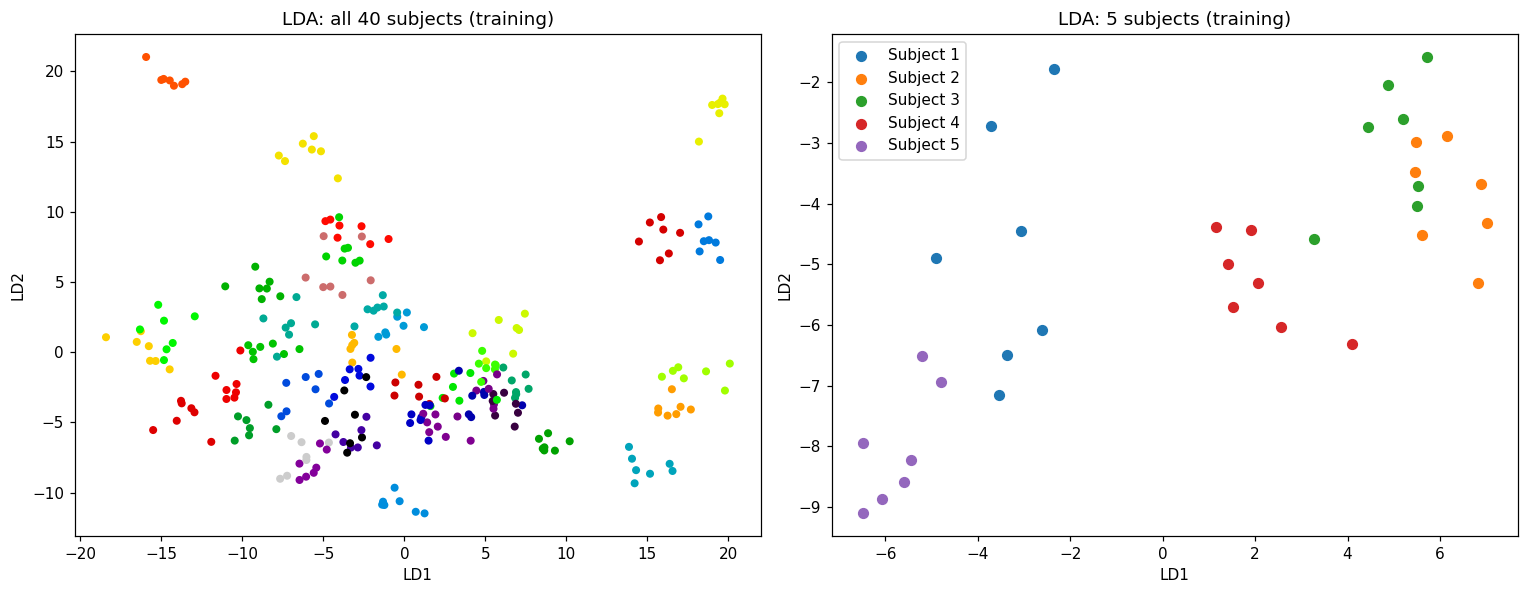

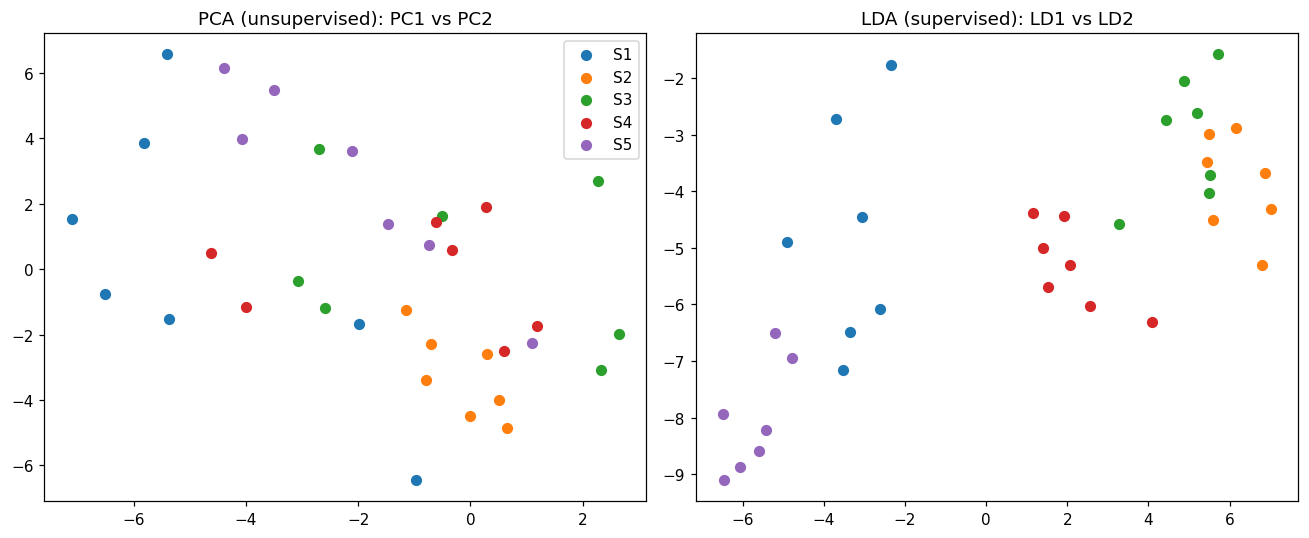

In [18]:
# ---- Visualise LDA projection (5 subjects for clarity, and all subjects) ----
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
sc = ax[0].scatter(Ltr[:, 0], Ltr[:, 1], c=y_train, cmap="nipy_spectral", s=18)
ax[0].set_title("LDA: all 40 subjects (training)"); ax[0].set_xlabel("LD1"); ax[0].set_ylabel("LD2")

subset = [0, 1, 2, 3, 4]
for s in subset:
    m = y_train == s
    ax[1].scatter(Ltr[m, 0], Ltr[m, 1], s=40, label=f"Subject {s+1}")
ax[1].set_title("LDA: 5 subjects (training)"); ax[1].set_xlabel("LD1"); ax[1].set_ylabel("LD2"); ax[1].legend()
plt.tight_layout(); plt.show()

# PCA vs LDA 2-D side by side on same 5 subjects
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for s in subset:
    m = y_train == s
    ax[0].scatter(Z2[m, 0], Z2[m, 1], s=40, label=f"S{s+1}")
    ax[1].scatter(Ltr[m, 0], Ltr[m, 1], s=40, label=f"S{s+1}")
ax[0].set_title("PCA (unsupervised): PC1 vs PC2"); ax[1].set_title("LDA (supervised): LD1 vs LD2")
ax[0].legend(); plt.tight_layout(); plt.show()

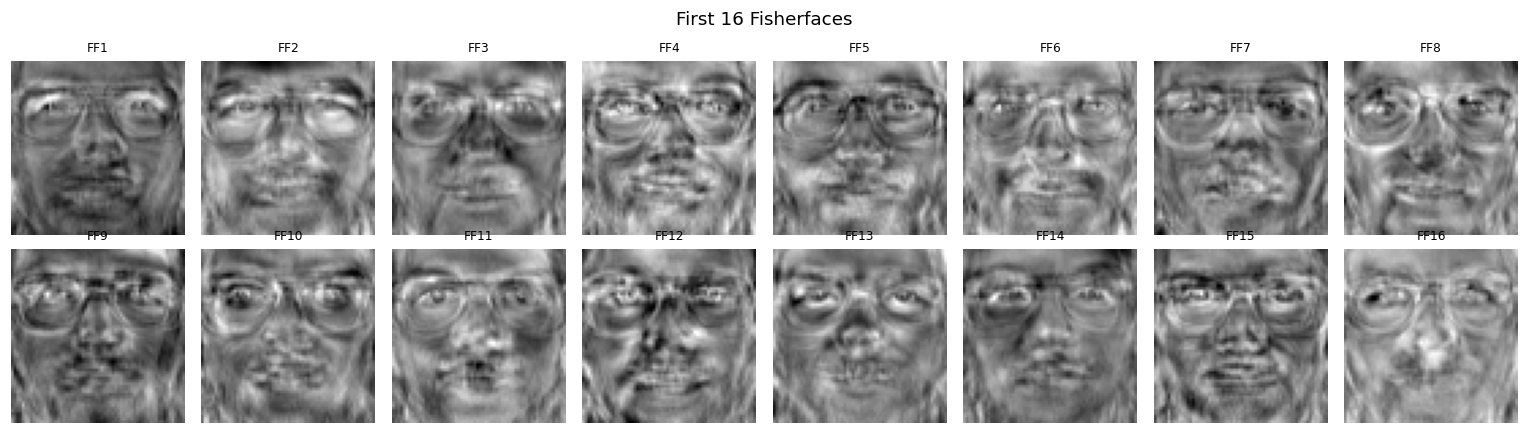

In [19]:
# ---- Fisherfaces: map LDA directions back to pixel space ----
fisherfaces = V_pca @ lda.scalings_[:, :n_classes - 1]
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(fisherfaces[:, i].reshape(IMG_SHAPE), cmap="gray"); ax.set_title(f"FF{i+1}", fontsize=8); ax.axis("off")
plt.suptitle("First 16 Fisherfaces"); plt.tight_layout(); plt.show()

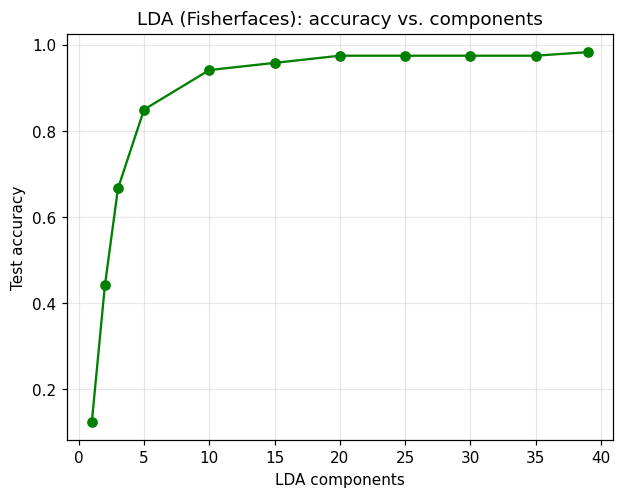

Best LDA setting: k=39, accuracy=0.9833


In [20]:
# ---- Accuracy vs number of LDA components ----
lda_ks = [1, 2, 3, 5, 10, 15, 20, 25, 30, 35, 39]
lda_accs = [knn_acc(Ltr[:, :k], Lte[:, :k]) for k in lda_ks]
plt.plot(lda_ks, lda_accs, "o-", c="green")
plt.xlabel("LDA components"); plt.ylabel("Test accuracy"); plt.title("LDA (Fisherfaces): accuracy vs. components")
plt.grid(alpha=.3); plt.show()
best_k_lda = lda_ks[int(np.argmax(lda_accs))]; best_acc_lda = max(lda_accs)
print(f"Best LDA setting: k={best_k_lda}, accuracy={best_acc_lda:.4f}")

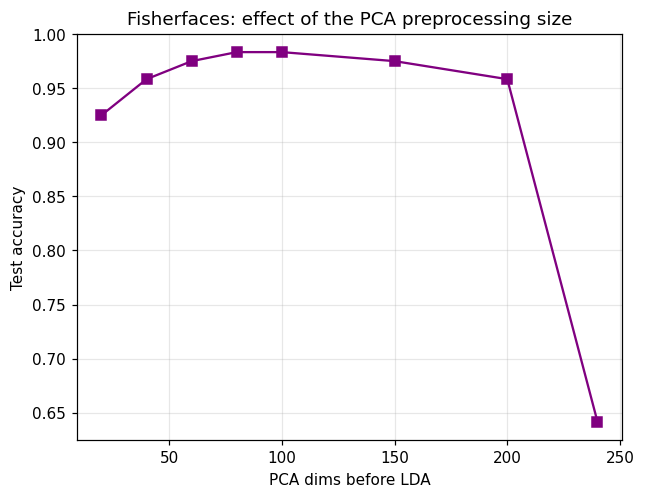

,PCA dims,LDA accuracy
0,20,0.9250
1,40,0.9583
2,60,0.9750
3,80,0.9833
4,100,0.9833
5,150,0.9750
6,200,0.9583
7,240,0.6417


In [21]:
# ---- Sensitivity to the number of PCA dims used before LDA ----
pre_dims = [20, 40, 60, 80, 100, 150, 200, 240]
res = []
for p in pre_dims:
    Ptr_p = (X_train - mean_face) @ V[:, :p]
    Pte_p = (X_test - mean_face) @ V[:, :p]
    m = LinearDiscriminantAnalysis(n_components=min(39, p)).fit(Ptr_p, y_train)
    res.append(m.score(Pte_p, y_test))
plt.plot(pre_dims, res, "s-", c="purple"); plt.xlabel("PCA dims before LDA"); plt.ylabel("Test accuracy")
plt.title("Fisherfaces: effect of the PCA preprocessing size"); plt.grid(alpha=.3); plt.show()
pd.DataFrame({"PCA dims": pre_dims, "LDA accuracy": np.round(res, 4)})

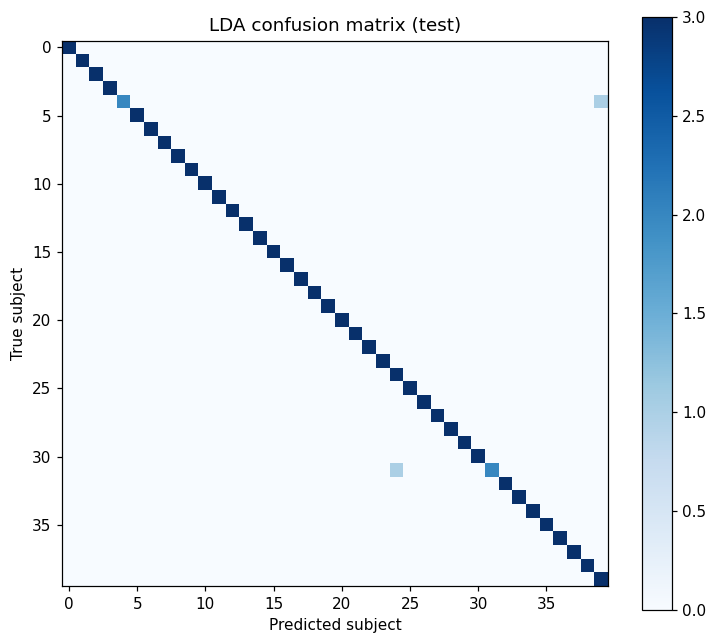

Misclassified test images: 2 of 120


In [22]:
# ---- Confusion matrix and report for the final LDA model ----
y_pred = lda.predict(Pte)
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 7)); plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.title("LDA confusion matrix (test)"); plt.xlabel("Predicted subject"); plt.ylabel("True subject"); plt.show()
print("Misclassified test images:", int((y_pred != y_test).sum()), "of", len(y_test))

## 7. Baseline Comparison (PCA, SVD, LDA)

,Method,Dimensions,Test accuracy
0,Raw pixels (no reduction),4096,0.9250
1,PCA + 1-NN,75,0.9333
2,SVD + 1-NN,75,0.9333
3,PCA + LDA (Fisherfaces) + 1-NN,39,0.9833


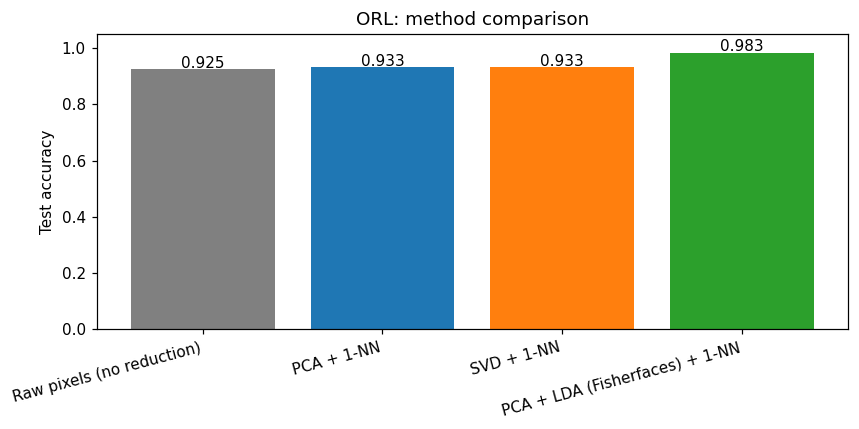

In [23]:
summary = pd.DataFrame([
    ["Raw pixels (no reduction)", n_features, base_acc],
    ["PCA + 1-NN",                best_k_pca, best_acc_pca],
    ["SVD + 1-NN",                best_k_svd, best_acc_svd],
    ["PCA + LDA (Fisherfaces) + 1-NN", best_k_lda, best_acc_lda],
], columns=["Method", "Dimensions", "Test accuracy"])
summary["Test accuracy"] = summary["Test accuracy"].round(4)
display(summary)

plt.figure(figsize=(8, 4))
bars = plt.bar(summary["Method"], summary["Test accuracy"], color=["gray", "tab:blue", "tab:orange", "tab:green"])
for b, a in zip(bars, summary["Test accuracy"]):
    plt.text(b.get_x() + b.get_width() / 2, a + 0.005, f"{a:.3f}", ha="center")
plt.ylim(0, 1.05); plt.ylabel("Test accuracy"); plt.xticks(rotation=15, ha="right")
plt.title("ORL: method comparison"); plt.tight_layout(); plt.show()

In [24]:
# ---- Effect of k (neighbours) and the data split: cross-validated robustness check ----
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
pipes = {
    "Raw + 1NN":       make_pipeline(KNeighborsClassifier(1)),
    f"PCA({best_k_pca}) + 1NN":  make_pipeline(PCA(best_k_pca), KNeighborsClassifier(1)),
    "PCA(100) + LDA":  make_pipeline(PCA(100), LinearDiscriminantAnalysis()),
}
cv_rows = []
for name, p in pipes.items():
    accs = []
    for tr, te in skf.split(X, y):
        p.fit(X[tr], y[tr]); accs.append(p.score(X[te], y[te]))
    cv_rows.append([name, np.mean(accs), np.std(accs)])
pd.DataFrame(cv_rows, columns=["Pipeline", "CV mean acc", "CV std"]).round(4)

,Pipeline,CV mean acc,CV std
0,Raw + 1NN,0.9450,0.0232
1,PCA(75) + 1NN,0.9450,0.0332
2,PCA(100) + LDA,0.9825,0.0061


## 8. FaceNet Embeddings (Deep Metric Learning)

PCA, SVD and LDA are **linear** projections of raw pixels. **FaceNet** (`InceptionResnetV1`, pre-trained on VGGFace2) maps a face to a
512-D embedding where **cosine / Euclidean distance directly measures identity similarity**. We use it as the final similarity engine.

**Install (once):**
```
pip install facenet-pytorch --no-deps      # keeps your existing torch; torch, torchvision, pillow, requests, tqdm must be installed
```
Pre-processing: 64x64 gray -> bilinear upsample to 160x160 -> replicate to 3 channels -> `(x-127.5)/128` (FaceNet standardisation).
> Tip: if you use the original 92x112 ORL images (`LOCAL_ORL_DIR`), accuracy is usually a bit better because less up-sampling is needed.

In [25]:
import torch, torch.nn.functional as F
from sklearn.preprocessing import normalize
try:
    from facenet_pytorch import InceptionResnetV1
except ImportError as e:
    raise ImportError("Run:  pip install facenet-pytorch --no-deps") from e

device = "cuda" if torch.cuda.is_available() else "cpu"
facenet = InceptionResnetV1(pretrained="vggface2").eval().to(device)   # downloads weights on first use
print("FaceNet loaded on", device)

@torch.no_grad()
def embed(images, batch=64):
    # images: (n, 4096) floats in [0, 1]  ->  (n, 512) L2-normalised FaceNet embeddings
    out = []
    for i in range(0, len(images), batch):
        b = torch.tensor(np.asarray(images[i:i + batch]), dtype=torch.float32).reshape(-1, 1, *IMG_SHAPE)
        b = F.interpolate(b, size=(160, 160), mode="bilinear", align_corners=False)
        b = b.repeat(1, 3, 1, 1).clamp(0, 1) * 255.0
        b = (b - 127.5) / 128.0
        out.append(facenet(b.to(device)).cpu().numpy())
    return normalize(np.vstack(out))

FaceNet loaded on cuda


In [26]:
# Same split as before, but keep indices so we can reuse embeddings of all images
idx_tr, idx_te = train_test_split(np.arange(n_samples), test_size=0.30, stratify=y, random_state=42)
assert np.allclose(X[idx_tr], X_train) and np.allclose(X[idx_te], X_test)

t0 = time.time()
emb_all = embed(X)
np.save("orl_facenet_embeddings.npy", emb_all)
E_train, E_test = emb_all[idx_tr], emb_all[idx_te]
print("Embeddings:", emb_all.shape, f"({time.time()-t0:.1f}s)  saved to orl_facenet_embeddings.npy")

Embeddings: (400, 512) (1.1s)  saved to orl_facenet_embeddings.npy


### 8.1 Classification with FaceNet (cosine similarity)

In [27]:
def cos_nn_acc(G, yg, Q, yq, k=1):
    clf = KNeighborsClassifier(n_neighbors=k, metric="cosine").fit(G, yg)
    return accuracy_score(yq, clf.predict(Q))

from sklearn.svm import SVC
fn_knn = cos_nn_acc(E_train, y_train, E_test, y_test)
fn_svm = SVC(kernel="linear").fit(E_train, y_train).score(E_test, y_test)
fn_lda = LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto").fit(E_train, y_train).score(E_test, y_test)

print(f"FaceNet + cosine 1-NN       : {fn_knn:.4f}")
print(f"FaceNet + linear SVM        : {fn_svm:.4f}")
print(f"FaceNet + shrinkage LDA     : {fn_lda:.4f}")
print(f"(for reference) best PCA {best_acc_pca:.4f} | SVD {best_acc_svd:.4f} | PCA+LDA {best_acc_lda:.4f}")

FaceNet + cosine 1-NN       : 1.0000
FaceNet + linear SVM        : 1.0000
FaceNet + shrinkage LDA     : 1.0000
(for reference) best PCA 0.9333 | SVD 0.9333 | PCA+LDA 0.9833


In [28]:
# k and distance-metric sensitivity: PCA features vs FaceNet
rows = []
Ptr_b = (X_train - mean_face) @ V[:, :best_k_pca]
Pte_b = (X_test - mean_face) @ V[:, :best_k_pca]
for name, (A, B) in {f"PCA({best_k_pca})": (Ptr_b, Pte_b), "FaceNet": (E_train, E_test)}.items():
    for metric in ["euclidean", "cosine"]:
        for k in [1, 3, 5]:
            clf = KNeighborsClassifier(n_neighbors=k, metric=metric).fit(A, y_train)
            rows.append([name, metric, k, round(clf.score(B, y_test), 4)])
pd.DataFrame(rows, columns=["features", "metric", "k", "accuracy"]).pivot_table(index=["features", "metric"], columns="k", values="accuracy")

k                        1       3       5
features metric                           
FaceNet  cosine     1.0000  1.0000  1.0000
         euclidean  1.0000  1.0000  1.0000
PCA(75)  cosine     0.9333  0.8500  0.7917
         euclidean  0.9333  0.8333  0.8000

### 8.2 Similarity Matrix and Genuine vs Impostor Distributions

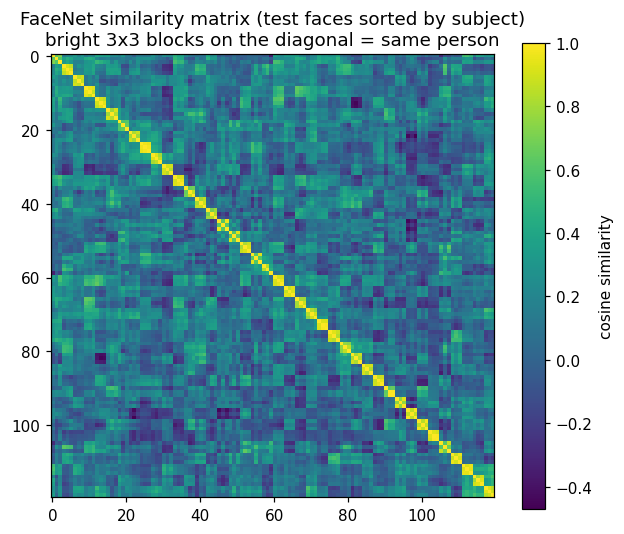

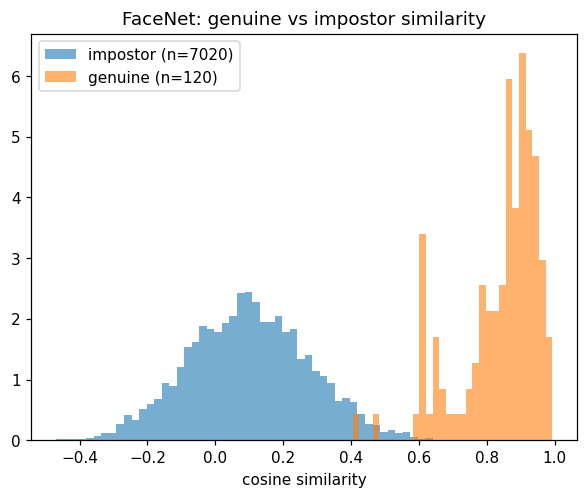

mean genuine = 0.837, mean impostor = 0.099


In [29]:
order = np.argsort(y_test, kind="stable")
S_fn = E_test[order] @ E_test[order].T
plt.figure(figsize=(6.5, 5.5))
plt.imshow(S_fn, cmap="viridis"); plt.colorbar(label="cosine similarity")
plt.title("FaceNet similarity matrix (test faces sorted by subject)\nbright 3x3 blocks on the diagonal = same person")
plt.show()

same = (y_test[:, None] == y_test[None, :])
iu = np.triu_indices(len(y_test), k=1)
S_raw = E_test @ E_test.T
gen, imp = S_raw[iu][same[iu]], S_raw[iu][~same[iu]]
plt.hist(imp, bins=50, alpha=.6, density=True, label=f"impostor (n={len(imp)})")
plt.hist(gen, bins=30, alpha=.6, density=True, label=f"genuine (n={len(gen)})")
plt.xlabel("cosine similarity"); plt.legend(); plt.title("FaceNet: genuine vs impostor similarity"); plt.show()
print(f"mean genuine = {gen.mean():.3f}, mean impostor = {imp.mean():.3f}")

### 8.3 Face Verification (same person or not?)
For every pair of test images we compute cosine similarity and evaluate with ROC / AUC / EER / TAR@FAR=1% for **all** representations
(raw pixels, PCA, LDA, FaceNet).

,AUC,EER,TAR@FAR=1%,EER threshold
Representation,,,,
Raw pixels,0.8877,0.1813,0.3500,0.2207
PCA(75),0.8903,0.1877,0.3833,0.2608
PCA+LDA,0.9920,0.0510,0.9333,0.3875
FaceNet,0.9994,0.0184,0.9833,0.4642


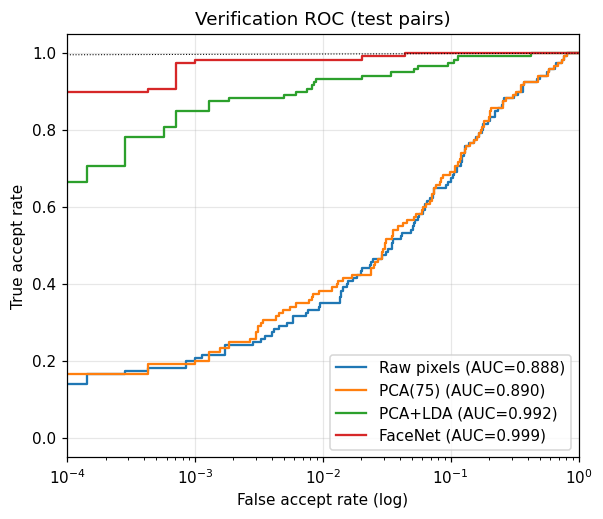

In [30]:
from sklearn.metrics import roc_curve, auc

def f_raw(A): return A - mean_face
def f_pca(A, k=None): return (A - mean_face) @ V[:, :(k or best_k_pca)]
def f_lda(A): return lda.transform((A - mean_face) @ V_pca)

reps_train = {"Raw pixels": f_raw(X_train), f"PCA({best_k_pca})": f_pca(X_train), "PCA+LDA": f_lda(X_train), "FaceNet": E_train}
reps_test  = {"Raw pixels": f_raw(X_test),  f"PCA({best_k_pca})": f_pca(X_test),  "PCA+LDA": f_lda(X_test),  "FaceNet": E_test}

def verification(Z, labels):
    Zn = normalize(Z); S = Zn @ Zn.T
    iu = np.triu_indices(len(Z), k=1)
    s = S[iu]; t = (labels[:, None] == labels[None, :])[iu].astype(int)
    fpr, tpr, thr = roc_curve(t, s)
    fnr = 1 - tpr; i = np.nanargmin(np.abs(fnr - fpr))
    return {"AUC": auc(fpr, tpr), "EER": (fpr[i] + fnr[i]) / 2, "TAR@FAR=1%": np.interp(0.01, fpr, tpr), "thr_eer": thr[i]}, (fpr, tpr)

ver_rows, rocs = [], {}
for name, Z in reps_test.items():
    m, rocs[name] = verification(Z, y_test)
    ver_rows.append([name] + [round(m[k], 4) for k in ["AUC", "EER", "TAR@FAR=1%", "thr_eer"]])
ver_df = pd.DataFrame(ver_rows, columns=["Representation", "AUC", "EER", "TAR@FAR=1%", "EER threshold"]).set_index("Representation")
display(ver_df)

plt.figure(figsize=(6, 5))
for name, (fpr, tpr) in rocs.items():
    plt.plot(fpr, tpr, label=f"{name} (AUC={ver_df.loc[name, 'AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k:", lw=.7); plt.xscale("log"); plt.xlim(1e-4, 1)
plt.xlabel("False accept rate (log)"); plt.ylabel("True accept rate"); plt.title("Verification ROC (test pairs)")
plt.legend(); plt.grid(alpha=.3); plt.show()
fn_thr = float(ver_df.loc["FaceNet", "EER threshold"])

### 8.4 Identification: CMC Curve (rank-k accuracy)

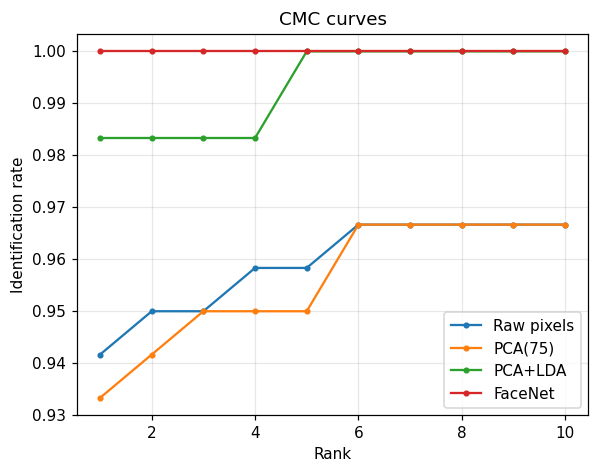

,rank-1,rank-3,rank-5,rank-10
Raw pixels,0.942,0.950,0.958,0.967
PCA(75),0.933,0.950,0.950,0.967
PCA+LDA,0.983,0.983,1.000,1.000
FaceNet,1.000,1.000,1.000,1.000


In [31]:
def cmc_curve(G, yg, Q, yq, max_rank=10):
    S = normalize(Q) @ normalize(G).T
    ranked = yg[np.argsort(-S, axis=1)]
    first = np.argmax(ranked == yq[:, None], axis=1)          # position of first correct image
    return np.array([(first < k).mean() for k in range(1, max_rank + 1)])

plt.figure(figsize=(6, 4.5))
cmc_rows = {}
for name in reps_test:
    c = cmc_curve(reps_train[name], y_train, reps_test[name], y_test)
    cmc_rows[name] = c; plt.plot(range(1, 11), c, "o-", ms=3, label=name)
plt.xlabel("Rank"); plt.ylabel("Identification rate"); plt.title("CMC curves"); plt.legend(); plt.grid(alpha=.3); plt.show()
pd.DataFrame(cmc_rows, index=[f"rank-{k}" for k in range(1, 11)]).T.round(3)[["rank-1", "rank-3", "rank-5", "rank-10"]]

### 8.5 Open-Set Recognition (reject unknown people)
Real systems must say **"unknown"**. We treat subjects 36-40 as *strangers*: they are removed from the gallery, and we sweep a similarity
threshold. DIR = correctly identified known faces accepted; FAR = unknown faces wrongly accepted.

Raw pixels   DIR at FAR<=5% : 0.590
PCA(75)      DIR at FAR<=5% : 0.714
PCA+LDA      DIR at FAR<=5% : 0.933
FaceNet      DIR at FAR<=5% : 1.000


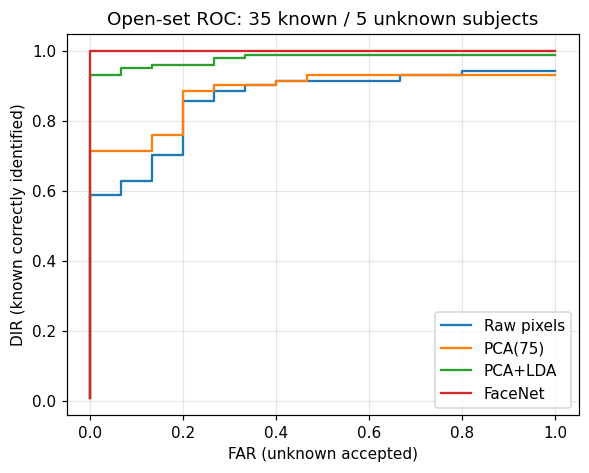

In [32]:
known = np.arange(35)
gmask = np.isin(y_train, known)
q_known = np.isin(y_test, known)

def open_set(G, yg, Q, yq):
    S = normalize(Q) @ normalize(G[gmask]).T
    best, pred = S.max(1), yg[gmask][S.argmax(1)]
    correct = q_known & (pred == yq)
    thr = np.unique(best)
    far = np.array([(best[~q_known] >= t).mean() for t in thr])
    dir_ = np.array([((best >= t) & correct).sum() / q_known.sum() for t in thr])
    return far, dir_

plt.figure(figsize=(6, 4.5))
for name in reps_test:
    far, d = open_set(reps_train[name], y_train, reps_test[name], y_test)
    ok = far <= 0.05
    print(f"{name:12s} DIR at FAR<=5% : {d[ok].max() if ok.any() else 0:.3f}")
    plt.plot(far, d, label=name)
plt.xlabel("FAR (unknown accepted)"); plt.ylabel("DIR (known correctly identified)")
plt.title("Open-set ROC: 35 known / 5 unknown subjects"); plt.legend(); plt.grid(alpha=.3); plt.show()

### 8.6 Final Similarity Finder: top-k most similar faces

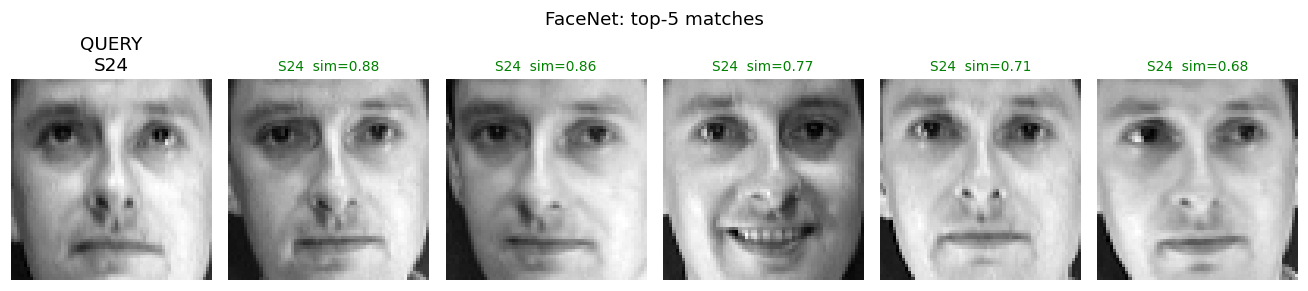

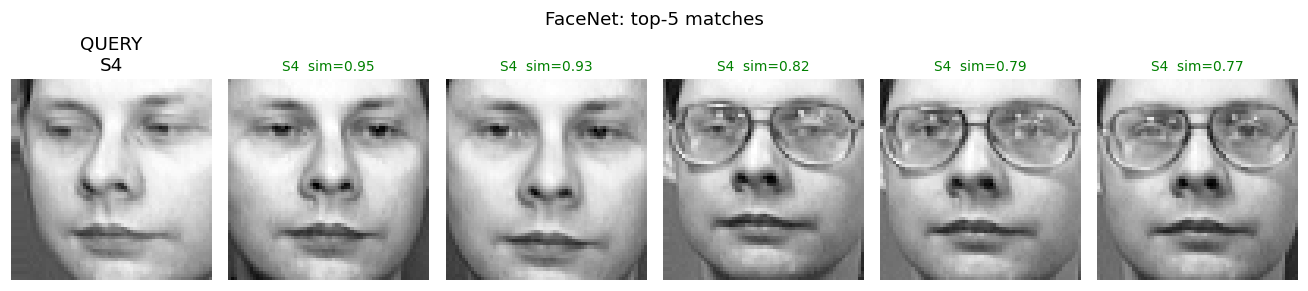

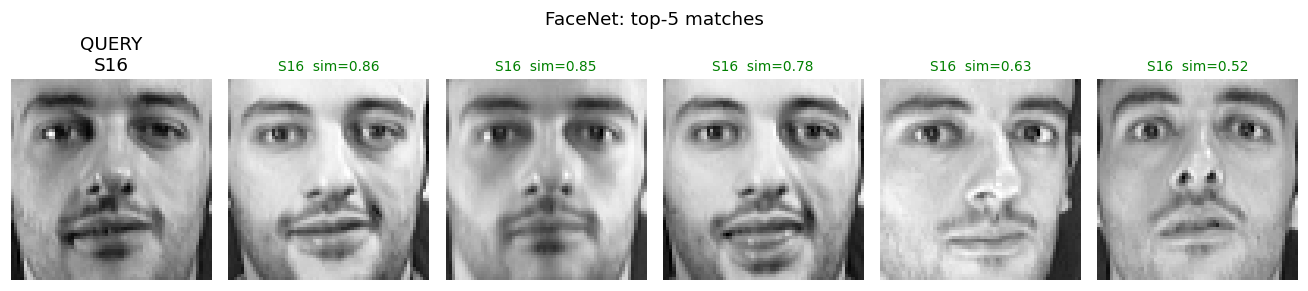

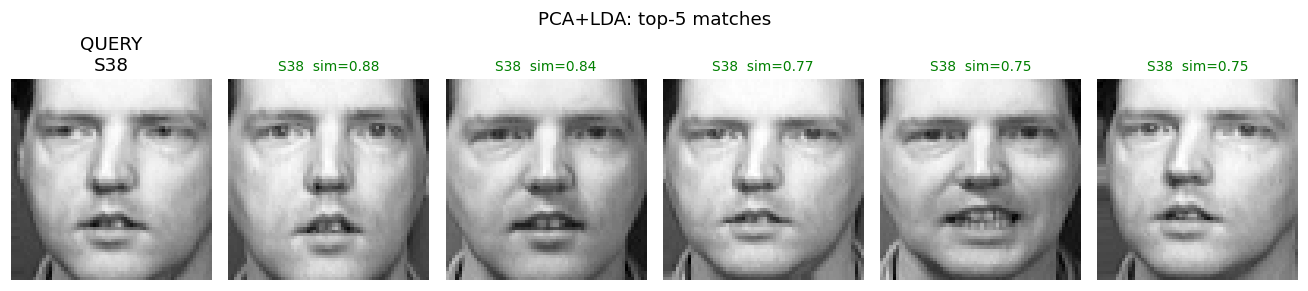

In [33]:
def top_matches(query_vec, gallery_vecs, topk=5):
    s = normalize(query_vec.reshape(1, -1)) @ normalize(gallery_vecs).T
    o = np.argsort(-s[0])[:topk]
    return o, s[0][o]

def show_matches(qi, rep="FaceNet", topk=5):
    # qi: index into the test set
    o, s = top_matches(reps_test[rep][qi], reps_train[rep], topk)
    fig, axes = plt.subplots(1, topk + 1, figsize=(2 * (topk + 1), 2.6))
    axes[0].imshow(X_test[qi].reshape(IMG_SHAPE), cmap="gray"); axes[0].set_title(f"QUERY\nS{y_test[qi]+1}"); axes[0].axis("off")
    for ax, j, sc in zip(axes[1:], o, s):
        ax.imshow(X_train[j].reshape(IMG_SHAPE), cmap="gray"); ax.axis("off")
        good = y_train[j] == y_test[qi]
        ax.set_title(f"S{y_train[j]+1}  sim={sc:.2f}", color="green" if good else "red", fontsize=9)
    plt.suptitle(f"{rep}: top-{topk} matches", y=1.02); plt.tight_layout(); plt.show()

rng = np.random.RandomState(1)
for qi in rng.choice(len(y_test), 3, replace=False):
    show_matches(qi, "FaceNet")

# Same query with the linear methods for comparison
show_matches(int(rng.choice(len(y_test))), "PCA+LDA")

In [34]:
# Failure analysis: test faces FaceNet gets wrong
fn_pred = KNeighborsClassifier(1, metric="cosine").fit(E_train, y_train).predict(E_test)
wrong = np.where(fn_pred != y_test)[0]
print(f"FaceNet errors: {len(wrong)} / {len(y_test)}")
for qi in wrong[:3]:
    show_matches(qi, "FaceNet", topk=4)

FaceNet errors: 0 / 120


In [35]:
# Production-style helper: identify one image with an accept/reject threshold
def identify_face(img_vec, threshold=None, rep_gallery=E_train, labels=y_train):
    threshold = fn_thr if threshold is None else threshold
    e = embed(img_vec.reshape(1, -1))
    o, s = top_matches(e[0], rep_gallery, 1)
    subject = int(labels[o[0]]) + 1
    return {"best_subject": subject, "similarity": float(s[0]), "decision": f"Subject {subject}" if s[0] >= threshold else "UNKNOWN"}

print("EER threshold from verification:", round(fn_thr, 3))
for i in [0, 7, 42]:
    print(f"test image {i} (true S{y_test[i]+1}) ->", identify_face(X_test[i]))

EER threshold from verification: 0.464
test image 0 (true S31) -> {'best_subject': 31, 'similarity': 0.9456398487091064, 'decision': 'Subject 31'}
test image 7 (true S38) -> {'best_subject': 38, 'similarity': 0.9691458940505981, 'decision': 'Subject 38'}
test image 42 (true S29) -> {'best_subject': 29, 'similarity': 0.9455820322036743, 'decision': 'Subject 29'}


### 8.7 Score-level Fusion: FaceNet + LDA similarities

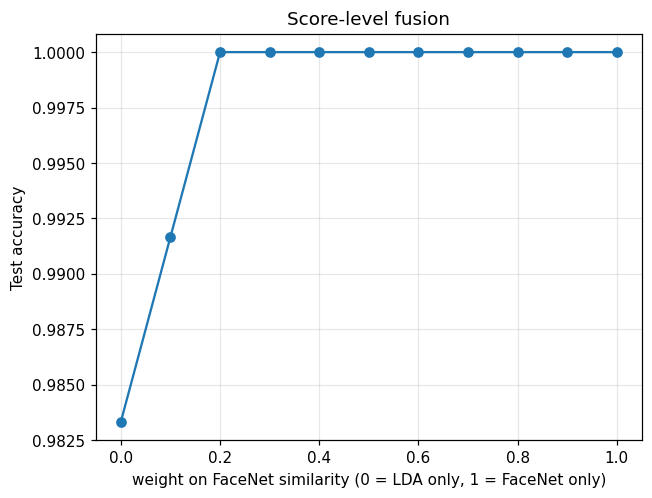

Best fusion weight = 0.2, accuracy = 1.0000


In [36]:
def zscore(M): return (M - M.mean()) / M.std()
S_fn_tt = normalize(E_test) @ normalize(E_train).T
S_ld_tt = normalize(reps_test["PCA+LDA"]) @ normalize(reps_train["PCA+LDA"]).T
ws = np.linspace(0, 1, 11)
fuse_accs = [accuracy_score(y_test, y_train[np.argmax(w * zscore(S_fn_tt) + (1 - w) * zscore(S_ld_tt), axis=1)]) for w in ws]
plt.plot(ws, fuse_accs, "o-"); plt.xlabel("weight on FaceNet similarity (0 = LDA only, 1 = FaceNet only)")
plt.ylabel("Test accuracy"); plt.title("Score-level fusion"); plt.grid(alpha=.3); plt.show()
best_acc_fuse = max(fuse_accs); best_w = ws[int(np.argmax(fuse_accs))]
print(f"Best fusion weight = {best_w:.1f}, accuracy = {best_acc_fuse:.4f}")

## 9. Additional Analyses

### 9.1 Embedding Visualisation with t-SNE (15 subjects)

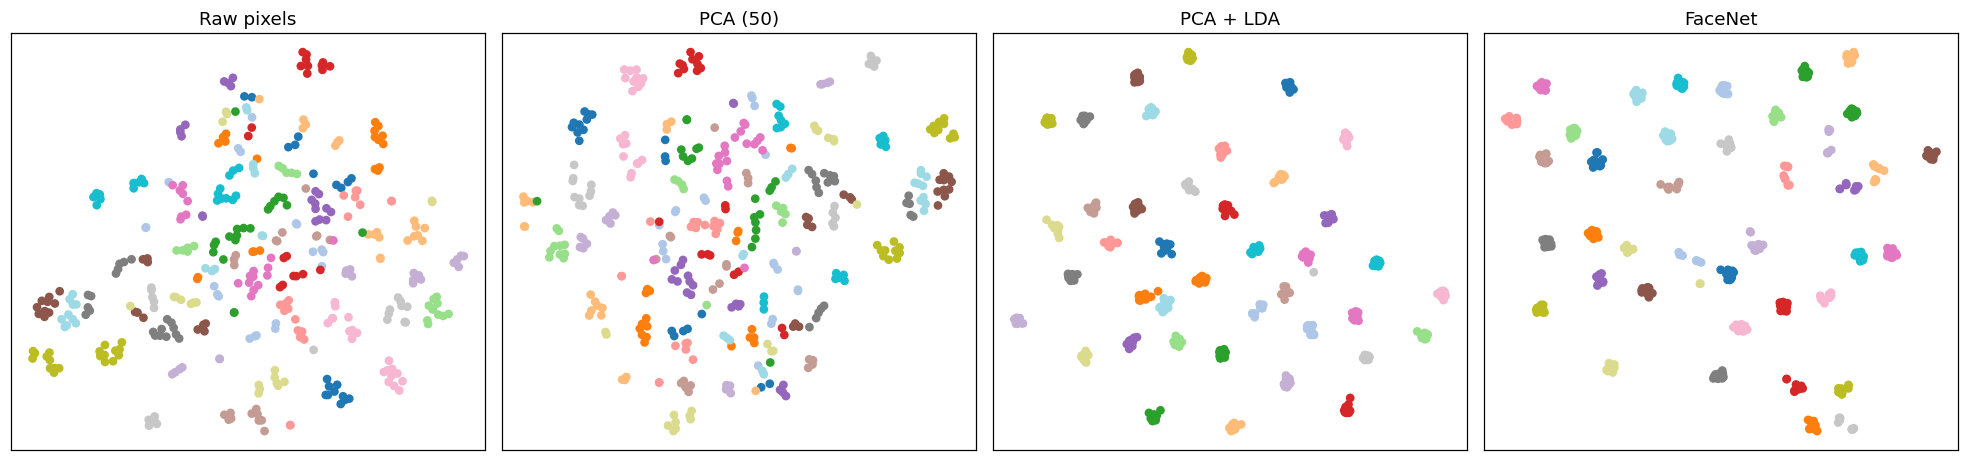

In [49]:
from sklearn.manifold import TSNE
sel = np.where(y < 100)[0]
spaces = {
    "Raw pixels": X[sel],
    "PCA (50)": f_pca(X[sel], 50),
    "PCA + LDA": f_lda(X[sel]),
    "FaceNet": emb_all[sel],
}
fig, axes = plt.subplots(1, 4, figsize=(18, 4.3))
for ax, (name, Z) in zip(axes, spaces.items()):
    T = TSNE(n_components=2, perplexity=20, random_state=0, init="pca").fit_transform(Z)
    ax.scatter(T[:, 0], T[:, 1], c=y[sel], cmap="tab20", s=22); ax.set_title(name); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

### 9.2 Robustness to Noise, Occlusion and Lighting

,Raw 1-NN,PCA(75),PCA+LDA,FaceNet
clean,0.925,0.933,0.983,1.000
noise s=0.1,0.925,0.933,0.975,0.067
noise s=0.25,0.900,0.908,0.967,0.033
eye occlusion,0.175,0.158,0.200,0.733
dark (x0.5),0.050,0.058,0.142,1.000
bright (x1.6),0.033,0.033,0.617,0.983


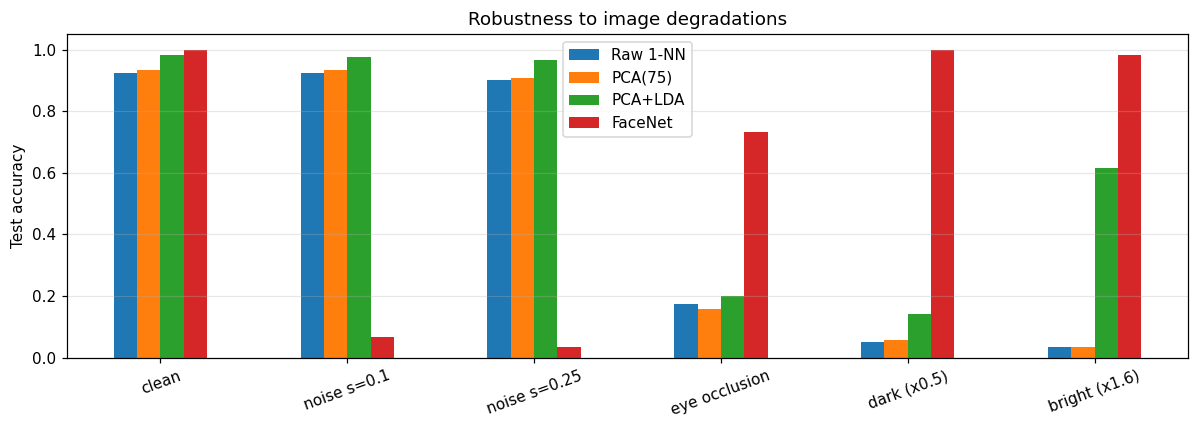

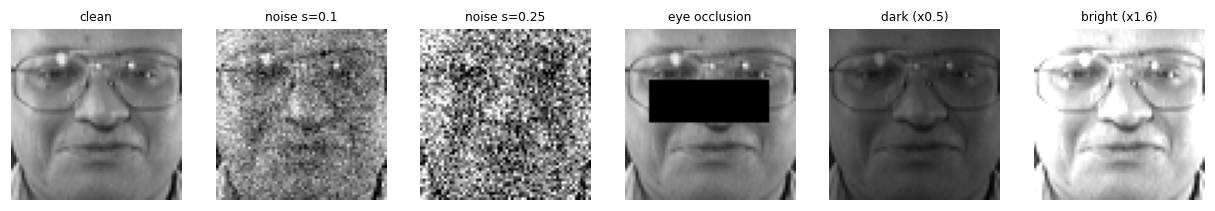

In [38]:
rs = np.random.RandomState(0)
def add_noise(A, s): return np.clip(A + rs.randn(*A.shape) * s, 0, 1)
def occlude(A):
    B = A.copy().reshape(-1, *IMG_SHAPE); h, w = IMG_SHAPE
    B[:, int(.30*h):int(.55*h), int(.15*w):int(.85*w)] = 0          # black band over the eyes
    return B.reshape(len(A), -1)
perturb = {
    "clean": lambda A: A,
    "noise s=0.1": lambda A: add_noise(A, .1),
    "noise s=0.25": lambda A: add_noise(A, .25),
    "eye occlusion": occlude,
    "dark (x0.5)": lambda A: np.clip(A * 0.5, 0, 1),
    "bright (x1.6)": lambda A: np.clip(A * 1.6, 0, 1),
}
clf_raw = KNeighborsClassifier(1).fit(X_train, y_train)
clf_pca = KNeighborsClassifier(1).fit(f_pca(X_train), y_train)
clf_fn  = KNeighborsClassifier(1, metric="cosine").fit(E_train, y_train)

rob = {}
for pname, fn in perturb.items():
    Xp = fn(X_test)
    rob[pname] = {
        "Raw 1-NN": clf_raw.score(Xp, y_test),
        f"PCA({best_k_pca})": clf_pca.score(f_pca(Xp), y_test),
        "PCA+LDA": lda.score((Xp - mean_face) @ V_pca, y_test),
        "FaceNet": clf_fn.score(embed(Xp), y_test),
    }
rob_df = pd.DataFrame(rob).T
display(rob_df.round(3))
rob_df.plot(kind="bar", figsize=(11, 4)); plt.ylabel("Test accuracy"); plt.ylim(0, 1.05); plt.xticks(rotation=20)
plt.title("Robustness to image degradations"); plt.grid(alpha=.3, axis="y"); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, len(perturb), figsize=(14, 2.4))
for ax, (pname, fn) in zip(axes, perturb.items()):
    ax.imshow(fn(X_test[:1]).reshape(IMG_SHAPE), cmap="gray", vmin=0, vmax=1); ax.set_title(pname, fontsize=8); ax.axis("off")
plt.show()

### 9.3 Learning Curve: how many gallery images per subject are needed?

,PCA,PCA+LDA,FaceNet
images/subject,,,
2,0.675,0.258,0.992
3,0.792,0.300,0.992
4,0.833,0.850,1.000
5,0.867,0.933,1.000
6,0.892,0.942,1.000
7,0.933,0.983,1.000


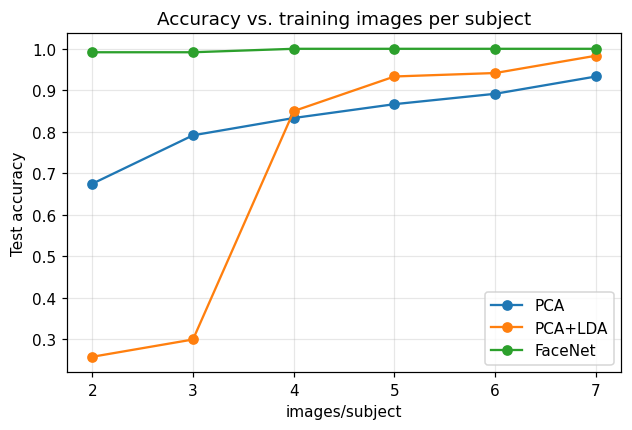

In [39]:
def subset_idx(n_per):
    return np.concatenate([np.where(y_train == c)[0][:n_per] for c in range(n_classes)])

lc = []
for n_per in range(2, 8):
    s = subset_idx(n_per); Xs, ys = X_train[s], y_train[s]
    p = min(len(s) - n_classes, 100)
    pca_s = PCA(p).fit(Xs)
    acc_lda = LinearDiscriminantAnalysis().fit(pca_s.transform(Xs), ys).score(pca_s.transform(X_test), y_test)
    pca_k = PCA(min(best_k_pca, len(s) - 1)).fit(Xs)
    acc_pca = KNeighborsClassifier(1).fit(pca_k.transform(Xs), ys).score(pca_k.transform(X_test), y_test)
    acc_fn = cos_nn_acc(E_train[s], ys, E_test, y_test)
    lc.append([n_per, acc_pca, acc_lda, acc_fn])
lc = pd.DataFrame(lc, columns=["images/subject", "PCA", "PCA+LDA", "FaceNet"]).set_index("images/subject")
display(lc.round(3))
lc.plot(marker="o", figsize=(6.5, 4)); plt.ylabel("Test accuracy"); plt.title("Accuracy vs. training images per subject"); plt.grid(alpha=.3); plt.show()

### 9.4 Cross-validated Comparison (5-fold, all 400 images)

In [40]:
cv_all = {"PCA + 1-NN": [], "PCA(100) + LDA": [], "FaceNet + cosine 1-NN": [], "FaceNet + shrinkage LDA": []}
for tr, te in skf.split(X, y):
    p = PCA(best_k_pca).fit(X[tr]); cv_all["PCA + 1-NN"].append(KNeighborsClassifier(1).fit(p.transform(X[tr]), y[tr]).score(p.transform(X[te]), y[te]))
    p = PCA(100).fit(X[tr]); cv_all["PCA(100) + LDA"].append(LinearDiscriminantAnalysis().fit(p.transform(X[tr]), y[tr]).score(p.transform(X[te]), y[te]))
    cv_all["FaceNet + cosine 1-NN"].append(cos_nn_acc(emb_all[tr], y[tr], emb_all[te], y[te]))
    cv_all["FaceNet + shrinkage LDA"].append(LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto").fit(emb_all[tr], y[tr]).score(emb_all[te], y[te]))
cv_df = pd.DataFrame({k: [np.mean(v), np.std(v)] for k, v in cv_all.items()}, index=["mean acc", "std"]).T.round(4)
cv_df

,mean acc,std
PCA + 1-NN,0.9475,0.0300
PCA(100) + LDA,0.9875,0.0079
FaceNet + cosine 1-NN,1.0000,0.0000
FaceNet + shrinkage LDA,0.9975,0.0050


## 10. Final Comparison of All Methods

,Method,Dims,Test accuracy,Verification AUC,Verification EER
0,Raw pixels + 1-NN,4096,0.9250,0.8877,0.1813
1,PCA + 1-NN,75,0.9333,0.8903,0.1877
2,SVD + 1-NN (same subspace as PCA),75,0.9333,0.8903,0.1877
3,PCA + LDA (Fisherfaces),39,0.9833,0.9920,0.0510
4,FaceNet + cosine 1-NN,512,1.0000,0.9994,0.0184
5,FaceNet + linear SVM,512,1.0000,NaN,NaN
6,FaceNet + shrinkage LDA,512,1.0000,NaN,NaN
7,Fusion FaceNet/LDA (w=0.2),-,1.0000,NaN,NaN


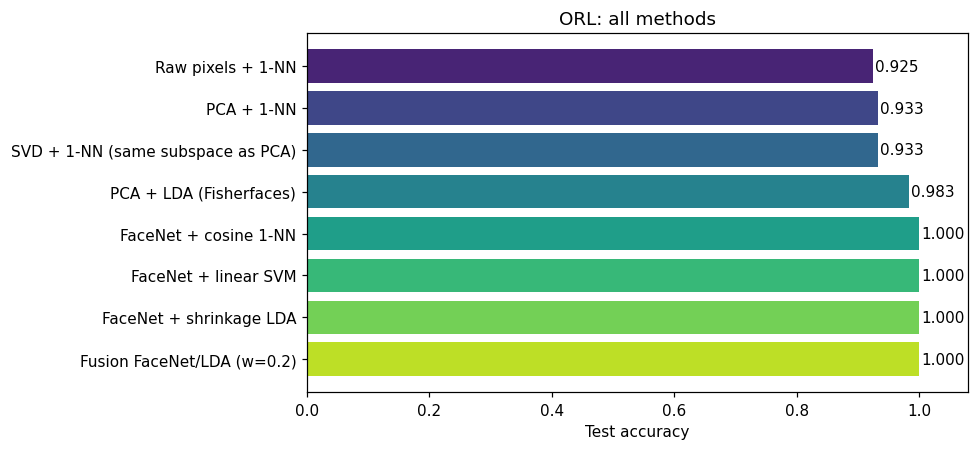

In [41]:
final = pd.DataFrame([
    ["Raw pixels + 1-NN",                 n_features, base_acc, np.nan, np.nan],
    ["PCA + 1-NN",                        best_k_pca, best_acc_pca, ver_df.loc[f"PCA({best_k_pca})", "AUC"], ver_df.loc[f"PCA({best_k_pca})", "EER"]],
    ["SVD + 1-NN (same subspace as PCA)", best_k_svd, best_acc_svd, ver_df.loc[f"PCA({best_k_pca})", "AUC"], ver_df.loc[f"PCA({best_k_pca})", "EER"]],
    ["PCA + LDA (Fisherfaces)",           best_k_lda, best_acc_lda, ver_df.loc["PCA+LDA", "AUC"], ver_df.loc["PCA+LDA", "EER"]],
    ["FaceNet + cosine 1-NN",             512, fn_knn, ver_df.loc["FaceNet", "AUC"], ver_df.loc["FaceNet", "EER"]],
    ["FaceNet + linear SVM",              512, fn_svm, np.nan, np.nan],
    ["FaceNet + shrinkage LDA",           512, fn_lda, np.nan, np.nan],
    [f"Fusion FaceNet/LDA (w={best_w:.1f})", "-", best_acc_fuse, np.nan, np.nan],
], columns=["Method", "Dims", "Test accuracy", "Verification AUC", "Verification EER"])
ver_raw = ver_df.loc["Raw pixels"]
final.loc[0, ["Verification AUC", "Verification EER"]] = [ver_raw["AUC"], ver_raw["EER"]]
display(final.round(4))

plt.figure(figsize=(9, 4.2))
bars = plt.barh(final["Method"][::-1], final["Test accuracy"][::-1], color=plt.cm.viridis(np.linspace(0.1, 0.9, len(final)))[::-1])
for b, a in zip(bars, final["Test accuracy"][::-1]):
    plt.text(a + 0.003, b.get_y() + b.get_height() / 2, f"{a:.3f}", va="center")
plt.xlim(0, 1.08); plt.xlabel("Test accuracy"); plt.title("ORL: all methods"); plt.tight_layout(); plt.show()

## 11. Conclusions

* **PCA** gives a compact, noise-reducing representation (eigenfaces) at similar or better accuracy than raw pixels. **SVD** of the centred data produces the same subspace (`σ²/(n-1)` = PCA eigenvalues) and is the numerically preferred way to compute it and to build low-rank approximations.
* **LDA / Fisherfaces** uses labels to separate identities with at most `C-1 = 39` dimensions. It needs PCA first (small-sample-size problem) and is typically the best of the three classical linear methods.
* **FaceNet** embeddings are trained for identity similarity, so cosine similarity is expected to separate *genuine* from *impostor* pairs better (higher AUC, lower EER, higher DIR in open-set tests) and to degrade less under noise and lighting changes than raw-pixel methods. **Check the tables above for your actual numbers and edit this paragraph if your results differ.**
* **Final similarity finder:** FaceNet cosine similarity (optionally fused with LDA scores) + a threshold from the verification EER gives a full identify / reject-unknown pipeline (`identify_face`).
* **Limitations:** ORL is tiny and frontal, so most methods score high; the 64x64 version is up-sampled to 160x160 for FaceNet; results depend on the split (see the cross-validation table). FaceNet was pre-trained on VGGFace2, whereas PCA/LDA learn only from these 280 images, so the comparison is between a transfer-learning model and models fit on the ORL training set alone.
* **Other possible extensions:** MTCNN face alignment on original 92x112 images, fine-tuning FaceNet on ORL, kernel PCA / kernel LDA, or LBP/HOG features.